#Лабораторная работа: От Bag of Words к смысловым пространствам


##Цель
Проследить эволюцию методов представления текста от частотных подходов к смысловым на практике

In [ ]:
!pip install gensim scikit-learn matplotlib numpy

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from collections import Counter
import re
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 37.7 MB/s eta 0:00:00


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

##Реализация SimpleBagOfWords

In [ ]:
class SimpleBagOfWords:
    def __init__(self):
        self.vocabulary = {}
        self.word_index = {}
        self.vocab_size = 0

    def preprocess_text(self, text):
        """Предобработка текста: приведение к нижнему регистру и удаление лишних символов"""
        # - Привести к нижнему регистру
        # - Удалить лишние символы (знаки препинания)
        return text

    def fit(self, texts):
        """
        Составляет словарь уникальных слов
        texts - список текстов
        """
        all_words = []
        for text in texts:
            processed_text = self.preprocess_text(text)
            words = processed_text.split()
            all_words.extend(words)


        # TODO: Создать словарь уникальных слов
        # - Найти уникальные слова
        # - Найти размер словаря
        unique_words =
        self.vocab_size =

        # Создаем mapping слово -> индекс и индекс -> слово
        self.vocabulary = {word: idx for idx, word in enumerate(unique_words)}
        self.word_index = {idx: word for idx, word in enumerate(unique_words)}

        return self

    def transform(self, texts):
        """
        Преобразует тексты в векторы BoW
        """
        vectors = []
        for text in texts:
            processed_text = self.preprocess_text(text)
            words = processed_text.split()

            # Создаем вектор нулей
            vector = [0] * self.vocab_size

            for word in words:
              # TODO Заполнить вектор частотами слов

            vectors.append(vector)

        return np.array(vectors)

    def fit_transform(self, texts):
        """Обучение и преобразование в одном методе"""
        self.fit(texts)
        return self.transform(texts)

    def get_feature_names(self):
        """Возвращает список всех слов в словаре"""
        return list(self.vocabulary.keys())

##РАЗДЕЛ 2: ТЕСТИРОВАНИЕ И ДЕМОНСТРАЦИЯ ОГРАНИЧЕНИЙ BOW

In [ ]:
# Тестовые примеры для демонстрации ограничений BoW
test_texts = [
    "собака укусила человека",
    "человек укусил собаку",
    "стреляю из лука",
    "плачу от лука",
    "люблю смотреть фильмы",
    "фильмы смотреть люблю"
]

In [ ]:
# Создаем и обучаем модель BoW
bow_model = SimpleBagOfWords()
vectors = bow_model.fit_transform(test_texts)

In [ ]:
# Создаем и обучаем модель BoW
bow_model = SimpleBagOfWords()
vectors = bow_model.fit_transform(test_texts)

print("Словарь:", bow_model.get_feature_names())
print("Размер словаря:", bow_model.vocab_size)
print("Векторы BoW:")
for i, text in enumerate(test_texts):
    print(f"'{text}': {vectors[i]}")

##РАЗДЕЛ 3: ДЕМОНСТРАЦИЯ ОГРАНИЧЕНИЙ BOW

In [ ]:
# Потеря порядка слов
# TODO возьмите два вектора (схожие слова в фразах, разный порядок), выведите на экран, проверьте равентво np.array_equal

In [ ]:
# Игнорирование контекста:
# TODO возьмите два вектора (схожие слова в фразах, разный контекст), проверьте, появляется ли в обоих фразах

##РАЗДЕЛ 4: ВИЗУАЛИЗАЦИЯ BOW-ВЕКТОРОВ

In [ ]:
def visualize_bow_vectors(texts, vectors, title="Визуализация BoW-векторов"):
    """Визуализация BoW-векторов с помощью PCA"""

    # Используем PCA для снижения размерности до 2D
    pca = PCA(n_components=2)
    vectors_2d = pca.fit_transform(vectors)

    # Создаем график
    plt.figure(figsize=(12, 8))

    # Разные цвета для разных групп текстов
    colors = ['red', 'red', 'blue', 'blue', 'green', 'green']

    # TODO: Реализовать визуализацию точек и аннотаций
    for i, (text, color) in enumerate(zip(texts, colors)):
        # TODO: Реализовать визуализацию точек и аннотаций
        x, y =
        plt.scatter()

        # Аннотируем точку текстом (обрезаем для читаемости)
        short_text =
        plt.annotate(short_text, (x, y), xytext=(5, 5),
                    textcoords='offset points', fontsize=9)


    plt.xlabel('Компонента PCA 1')
    plt.ylabel('Компонента PCA 2')
    plt.title(title)
    plt.grid(True, alpha=0.3)

    # Добавляем легенду
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='red', label='Укусы'),
        Patch(facecolor='blue', label='Лук'),
        Patch(facecolor='green', label='Фильмы')
    ]
    plt.legend(handles=legend_elements)

    plt.show()

    # Выводим объяснение PCA
    print(f"Объясненная дисперсия: {pca.explained_variance_ratio_}")
    print(f"Суммарная объясненная дисперсия: {sum(pca.explained_variance_ratio_):.3f}")

In [ ]:
# Визуализируем BoW-векторы
visualize_bow_vectors(test_texts, vectors, "BoW-векторы (PCA)")

##РАЗДЕЛ 5: РАБОТА С WORD2VEC И ВИЗУАЛИЗАЦИЯ СЕМАНТИЧЕСКИХ ПРОСТРАНСТВ

In [ ]:
# Загружаем русскую модель Word2Vec

try:
    import gensim.downloader as api
    print("Загружаем модель")
    word2vec_model = api.load('word2vec-ruscorpora-300')
except Exception as e:
    print(f"Не удалось загрузить {e}")


##Демонстрация векторных операций в Word2Vec для модели с тегами частей речи

In [ ]:
def demonstrate_vector_arithmetic_with_tags(model):

    # Примеры с учетом тегов частей речи
    examples = [
        # Существительные
        (['король_NOUN', 'женщина_NOUN'], ['мужчина_NOUN'], 'королева_NOUN'),
        (['отец_NOUN', 'дочь_NOUN'], ['сын_NOUN'], 'мать_NOUN'),
        #TODO Добавить существительные

        #TODO Добавить прилагательные
        (['большой_ADJ', 'хороший_ADJ'], ['маленький_ADJ'], 'плохой_ADJ'),

        #TODO Добавить глаголы
        (['бежать_VERB', 'стоять_VERB'], ['стоять_VERB'], 'бежать_VERB'),

        #TODO Добавить аналогии
        (['день_NOUN', 'ночь_NOUN'], ['ночь_NOUN'], 'день_NOUN')

    ]

In [ ]:
for pos, neg, expected in examples:
      try:
          # TODO: Реализовать векторную арифметику
          # - Проверить наличие слов в модели
          # - Выполнить операцию most_similar model.most_similar(positive, negative, topn)
          # - Вывести топ 5 результатов
          pass

      except Exception as e:
          print(f" Ошибка для {pos} - {neg}: {e}")

In [ ]:
# Демонстрируем векторную арифметику с тегами
demonstrate_vector_arithmetic_with_tags(word2vec_model)

##Поиск семантически близких слов для модели с тегами

In [ ]:
def find_similar_words_with_tags(model, word, topn=8):
    """
    Поиск семантически близких слов для модели с тегами
    """
    print(f"Слова, близкие к '{word}'")
    try:
         # TODO: Реализовать поиск похожих слов
          # - Проверить наличие слова в модели
          # - Найти наиболее похожие слова
          # - Вывести результаты
    except Exception as e:
        print(f" Ошибка при поиске похожих слов: {e}")

In [ ]:
# Поиск семантически близких слов с тегами
find_similar_words_with_tags(word2vec_model, 'человек_NOUN')
find_similar_words_with_tags(word2vec_model, 'говорить_VERB')
find_similar_words_with_tags(word2vec_model, 'большой_ADJ')
find_similar_words_with_tags(word2vec_model, 'хороший_ADJ')

##Визуализация семантических отношений в Word2Vec для модели с тегами

In [ ]:
def visualize_word2vec_with_tags(model):
    """
    Визуализация семантических отношений в Word2Vec для модели с тегами
    """

    # Группы слов с тегами, которые должны быть в модели
    #TODO Добавить свои слова

    word_groups = {
        'nouns_people': ['человек_NOUN', 'люди_NOUN', 'личность_NOUN', 'персона_NOUN'],
        'nouns_time': ['время_NOUN', 'год_NOUN', 'день_NOUN', 'месяц_NOUN'],
        'verbs_action': ['говорить_VERB', 'сказать_VERB', 'молчать_VERB', 'кричать_VERB'],
        'adjectives_size': ['большой_ADJ', 'маленький_ADJ', 'огромный_ADJ', 'крошечный_ADJ'],
        'adjectives_quality': ['хороший_ADJ', 'плохой_ADJ', 'отличный_ADJ', 'ужасный_ADJ']
    }

    # TODO: Реализовать визуализацию семантических пространств
    # - Собрать векторы для всех слов


    # Применение  t-SNE для снижения размерности
    # преобразуем список в numpy array перед t-SNE
    all_vectors_array = np.array(all_vectors)

    # Визуализация с помощью t-SNE
    tsne = TSNE(n_components=2, random_state=42, perplexity=min(5, len(all_vectors_array)-1))
    vectors_2d = tsne.fit_transform(all_vectors_array)  # Теперь передаем numpy array

    # Построение графика
    plt.figure(figsize=(14, 10))
    colors = ['red', 'blue', 'green', 'orange', 'purple', 'brown']

    # TODO:
    # - Группировать точки по категориям
    # - Визуализировать результаты (с помощью scatter)



In [ ]:
#Визуализируем Word2Vec пространства с тегами
visualize_word2vec_with_tags(word2vec_model)

Пример того, что должно получиться

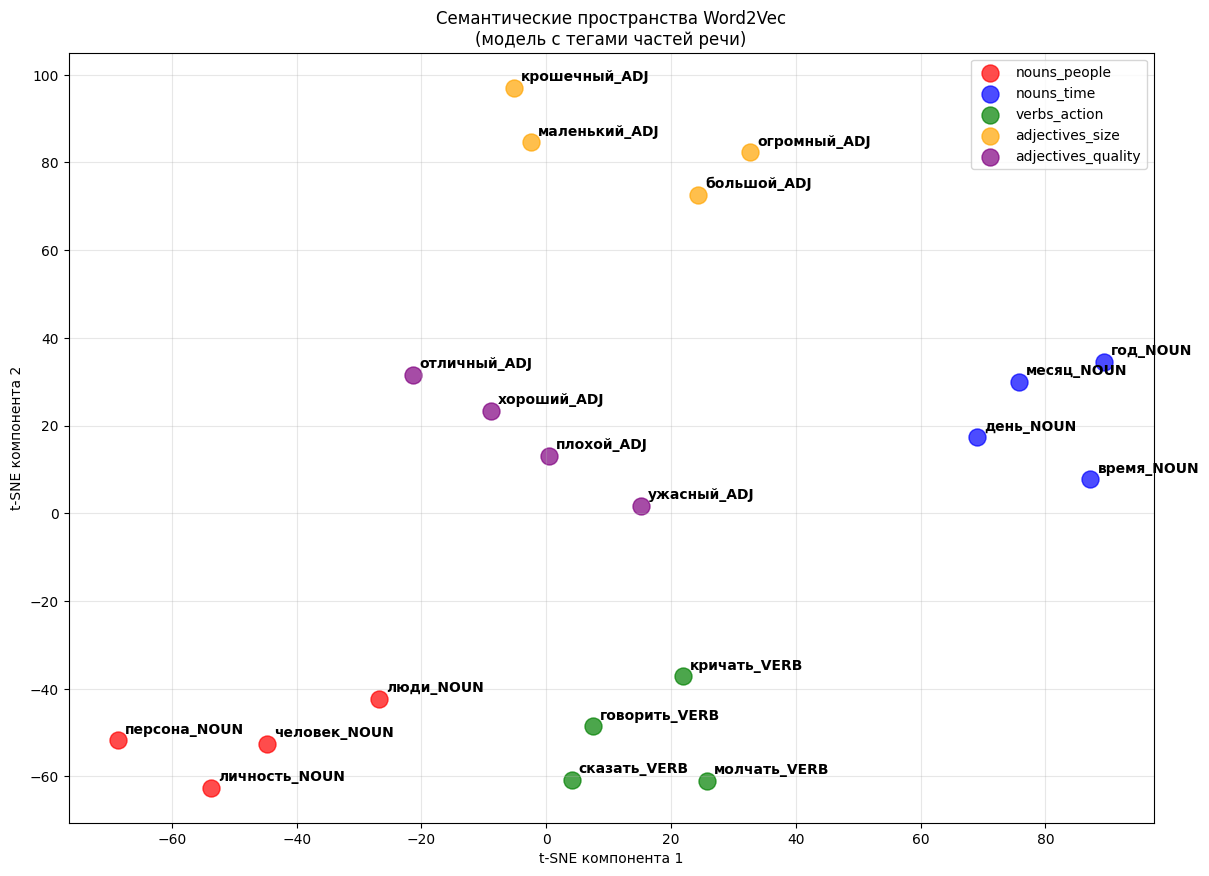

# TODO: Проанализировать результаты и сделать выводы

Bag of Words

Преимущества
1.   Новый пункт
2.   Новый пункт

Недостатки

1.   Новый пункт
2.   Новый пункт


Word2Vec

Преимущества
1.   Новый пункт
2.   Новый пункт

Недостатки
1.   Новый пункт
2.   Новый пункт
